---
code-fold: true
format:
  html: default
---

# The superalgebraic trapezoid rule {.unnumbered}

::: {.callout-note collapse="true" title="🤖 How/Why?"}

In last year's course, I wanted to talk about the *exponentially convergent trapezoid rule* but the proof requires the use of Fourier series and complex analysis, so I didn't. I recently realised we can get close (superalgebraic convergence) using more elementary methods (via the Euler–Maclaurin formula). 

I outlined this notebook and then let Claude convert the outline into a series of exercises and numerical experiments. I checked the results before publishing. As always, let me know if you find errors.

(This content is a "bonus"; the main lecture material is human-made and based on the course from previous years.)

:::

In [1]:
using Plots, Polynomials

Recall, from lectures, that we defined the composite trapezoid rule to be the (Newton--Cotes) quadrature rule by approximating integrals on subintervals by trapeziods: Let $[a,b]$ be a bounded interval, $x_j = a + jh$ with $n \geq 1$ and $h = \frac{b-a}{n}$, and define the composite trapezoid rule

$$
\begin{align}
I(f) &:= \int_a^b f(x) \mathrm{d}x \nonumber\\
&\approx I_n(f) := h \Big( \tfrac12 f(a) + \sum_{j=1}^{n-1} f(x_j) + \tfrac12 f(b) \Big).
\end{align}
$$

We saw in lectures that this rule converges with order $O(n^{-2})$ for functions with a continuous third derivative. Let's take a look at what happens for some other functions:

- $f(x) = e^{\sin x}$ on $[0, 2\pi]$: analytic and periodic,
- $f(x) = e^{-1/\sin^2 x}$ on $[0, 2\pi]$: smooth with vanishing derivatives at the boundary but *not* analytic,
- $f(x) = |\sin x|^3$ on $[0, 2\pi]$: periodic but only $C^2$ (the third derivative jumps at $x = 0, \pi, 2\pi$),
- $f(x) = e^x$ on $[0, 1]$: smooth but $f'(0) \neq f'(1)$.
- $f(x) = \sqrt{x}$ on $[0,1]$: continuous but with $f'(x) \to \infty$ as $x\to0$.

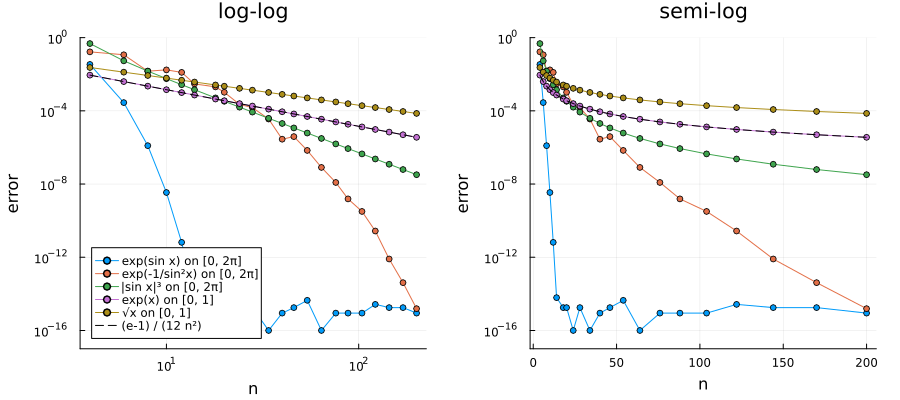

In [ ]:
trapezoid(f, a, b, n) = (b - a) / n * (sum(f, range(a, b, length = n + 1)) - (f(a) + f(b)) / 2)

f_analytic(x) = exp(sin(x))
f_bump(x) = exp(-1 / sin(x)^2)
f_rough(x) = abs(sin(x))^3
f_generic(x) = exp(x)
f_sqrt(x) = sqrt(x)

ns = unique(2 .* round.(Int, 10 .^ range(0.3, 2.0, length = 25)))    
errors(f, a, b, exact) = [max(abs(trapezoid(f, a, b, n) - exact), 1e-16) for n in ns]   

# the trapezoid rule is (much) more accurate than any n we plot, so use it with huge n as the "exact" value
exact_analytic = trapezoid(f_analytic, 0, 2π, 4000)
exact_bump     = trapezoid(f_bump,     0, 2π, 40000)
exact_rough    = 8 / 3                                                 
exact_generic = exp(1) - 1
exact_sqrt = 2/3 

function error_plot(; kwargs...)
    plot(ns, errors(f_analytic, 0, 2π, exact_analytic), label = "exp(sin x) on [0, 2π]", marker = :o, ms = 3)
    plot!(ns, errors(f_bump, 0, 2π, exact_bump), label = "exp(-1/sin²x) on [0, 2π]", marker = :o, ms = 3)
    plot!(ns, errors(f_rough, 0, 2π, exact_rough), label = "|sin x|³ on [0, 2π]", marker = :o, ms = 3)
    plot!(ns, errors(f_generic, 0, 1, exact_generic), label = "exp(x) on [0, 1]", marker = :o, ms = 3)
    plot!(ns, errors(f_sqrt, 0, 1, exact_sqrt), label = "√x on [0, 1]", marker = :o, ms = 3)
    plot!(ns, (ℯ - 1) ./ (12 .* ns .^ 2), label = "(e-1) / (12 n²)", ls = :dash, color = :black,
          xlabel = "n", ylabel = "error", ylims = (1e-17, 1), yticks = 10.0 .^ (-16:4:0); kwargs...)
end

plot(error_plot(xscale = :log10, yscale = :log10, legend = :bottomleft, title = "log-log"),
     error_plot(yscale = :log10, legend = false, title = "semi-log"),
     layout = (1, 2), size = (900, 400), margin = 4Plots.mm)

On the log-log plot (left) a rate $O(n^{-p})$ is a straight line of slope $-p$. The generic integrand $e^x$ follows the line $n^{-2}$, as @thm-trapezoid-composite predicts (the dashed line is its exact asymptotic error). The periodic but only $C^2$ integrand $|\sin x|^3$ is a straight line of slope $-4$: it converges at a *fixed* polynomial rate, faster than $n^{-2}$. The trapezoid rule for $\sqrt{x}$ converges with rate $O(n^{-\frac32})$ - explain why this doesn't contradict the theorem from lectures (can you prove the $O(n^{-\frac32})$ rate?). For the two smooth periodic integrands, the error curves bend downwards faster than any straight line (that is, they converge faster than any power of $n$). On the semi-log plot (right) a geometric rate $O(e^{-c n})$ is a straight line: this is what we see for the analytic integrand $e^{\sin x}$, which reaches machine precision by $n \approx 16$. The non-analytic function has a slower convergence (its curve bends upwards on the semi-log plot, so it is not geometric), but still decays faster than any power of $n$. We will prove the superalgebraic statement (the geometric rate is discussed at the end of the page):

::: {.theorem}

[Theorem (Superalgebraic convergence of the trapezoid rule)]{.theorem-title}

Let $f \in C^\infty([a,b])$ satisfy $f^{(k)}(a) = f^{(k)}(b)$ for every $k = 0, 1, 2, \dots$. Then for every $p \geq 1$ there is a constant $C_p$ (independent of $n$) such that

$$
\left| \int_a^b f - I_n f \right| \leq C_p n^{-p}
$$

for all $n \geq 1$. That is, the error decays faster than *any* power of $n$.

:::

The hypothesis says that all derivatives of $f$ match at the two ends of the interval, i.e. that $f$ extends to a smooth $(b-a)$-periodic function on $\mathbb R$. The proof uses the *Euler–Maclaurin formula*, whose remainder terms are most conveniently written with the *Bernoulli polynomials*, so we introduce those first.

## Bernoulli polynomials {.unnumbered}

::: {.theorem .definition}

[Definition (Bernoulli polynomials)]{.theorem-title}

The *Bernoulli polynomials* $B_0, B_1, B_2, \dots$ are defined by $B_0 = 1$ and, for $k \geq 1$,

$$
\begin{align}
    &B_k' = k B_{k-1}, \quad \text{and}\nonumber\\
    &\int_0^1 B_k(x) \,\mathrm{d}x = 0.
\end{align}
$$

The *Bernoulli numbers* are $b_k := B_k(0)$.

:::

::: {.theorem .exercise}

[Exercise: Existence, uniqueness and the first few]{.theorem-title}

1. Show that for every $n \geq 0$ there is exactly one polynomial $B_n$ satisfying the definition, and that it is monic of degree $n$.
2. Compute $B_1, B_2, B_3, B_4$ and the Bernoulli numbers $b_1,\dots,b_4$.

:::

<details class="exercise-hint"><summary>Hint</summary>

Suppose we have $B_{n-1}$. What does $B_n' = n B_{n-1}$ tell us about $B_n$ up to a constant? What fixes the constant?

</details>

<details class="exercise-solution"><summary>Solution</summary>

1. $B_0 = 1$ by definition. Suppose we have $B_{n-1}$, a monic polynomial of degree $n-1$. A polynomial $B_n$ with $B_n' = n B_{n-1}$ must satisfy

$$
B_n(x) = n \int_0^x B_{n-1}(t) \,\mathrm{d}t + c
$$

for a constant $c$, and conversely every such polynomial has $B_n' = nB_{n-1}$. The condition $\int_0^1 B_n = 0$ is a (non-degenerate) linear equation for $c$,

$$
c = -n \int_0^1 \int_0^x B_{n-1}(t) \,\mathrm{d}t \,\mathrm{d}x,
$$

so $c$, and hence $B_n$, is unique. Finally, $B_{n-1}$ is monic of degree $n-1$, so $n\int_0^x B_{n-1}$ is monic of degree $n$.

2. $B_1' = 1$ gives $B_1 = x + c$ and $\int_0^1 B_1 = \frac12 + c = 0$, so $B_1 = x - \frac12$. Then $B_2' = 2x - 1$ gives $B_2 = x^2 - x + c$ with $\frac13 - \frac12 + c = 0$, so $B_2 = x^2 - x + \frac16$. Next $B_3' = 3x^2 - 3x + \frac12$, so $B_3 = x^3 - \frac32 x^2 + \frac12 x + c$ with $\frac14 - \frac12 + \frac14 + c = 0$, i.e. $c = 0$. Finally $B_4' = 4x^3 - 6x^2 + 2x$, so $B_4 = x^4 - 2x^3 + x^2 + c$ with $\frac15 - \frac12 + \frac13 + c = 0$, i.e. $c = -\frac1{30}$. In summary

$$
\begin{align}
    B_1 &= x - \tfrac12, \\ 
    B_2 &= x^2 - x + \tfrac16, \\
    B_3 &= x^3 - \tfrac32 x^2 + \tfrac12 x, \\ 
    B_4 &= x^4 - 2x^3 + x^2 - \tfrac1{30},
\end{align}
$$

and $b_1 = -\frac12$, $b_2 = \frac16$, $b_3 = 0$, $b_4 = -\frac1{30}$.

</details>

Implementing this recursion gives the Bernoulli polynomials:

In [ ]:
function bernoulli_poly(n)
    B = Polynomial([1 // 1])
    for j ∈ 1:n
        P = j * integrate(B)           
        B = P - integrate(P)(1)    
    end
    B
end

for n ∈ 0:6
    println("B_$n = ", bernoulli_poly(n))
end
println("b_0, ..., b_8 = ", [bernoulli_poly(n)(0) for n ∈ 0:8])

B_0 = 1//1
B_1 = -1//2 + x
B_2 = 1//6 - x + x^2
B_3 = 1//2*x - 3//2*x^2 + x^3
B_4 = -1//30 + x^2 - 2//1*x^3 + x^4
B_5 = -1//6*x + 5//3*x^3 - 5//2*x^4 + x^5
B_6 = 1//42 - 1//2*x^2 + 5//2*x^4 - 3//1*x^5 + x^6
Bernoulli numbers b_0, ..., b_8 = Rational{Int64}[1, -1//2, 1//6, 0, -1//30, 0, 1//42, 0, -1//30]


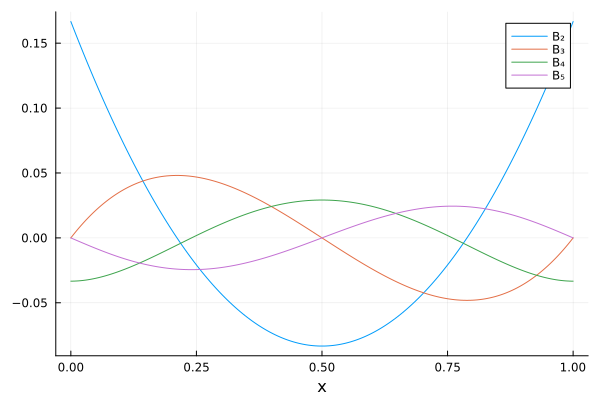

In [4]:
xs = range(0, 1, length = 200)
plot(xs, [bernoulli_poly(n).(xs) for n ∈ 2:5], label = ["B₂" "B₃" "B₄" "B₅"], xlabel = "x", legend = :topright)

::: {.theorem .exercise}

[Exercise: Endpoint values and symmetry]{.theorem-title}

Show that

1. $B_1(1) - B_1(0) = 1$, but $B_n(1) = B_n(0) = b_n$ for all $n \geq 2$,
2. $B_n(1 - x) = (-1)^n B_n(x)$ for all $n \geq 0$,
3. $b_n = 0$ for every odd $n \geq 3$.

:::

<details class="exercise-hint"><summary>Hint</summary>

1. Fundamental theorem of calculus applied to $B_n' = nB_{n-1}$, and the second defining property of $B_{n-1}$.
2. Show that $C_n(x) := (-1)^n B_n(1 - x)$ satisfies the same defining properties as $B_n$, and use the uniqueness from the previous exercise.
3. Combine the first two parts at $x = 0$.

</details>

<details class="exercise-solution"><summary>Solution</summary>

1. $B_n(1) - B_n(0) = \int_0^1 B_n'(x)\,\mathrm{d}x = n \int_0^1 B_{n-1}(x) \,\mathrm{d}x$. For $n = 1$ this is $\int_0^1 B_0 = 1$, while for $n \geq 2$ this vanishes by the definition of $B_{n-1}$ (since $n - 1 \geq 1$).

2. $C_0 = 1 = B_0$. For $n \geq 1$, by the chain rule,

$$
\begin{align}
    C_n'(x) &= (-1)^{n+1} B_n'(1-x) \nonumber\\
    &= (-1)^{n+1} n B_{n-1}(1-x) \nonumber\\
    &= n\, (-1)^{n-1} B_{n-1}(1-x) \nonumber\\
    &= n C_{n-1}(x),
\end{align}
$$

and, substituting $x \mapsto 1 - x$, $\int_0^1 C_n = (-1)^n \int_0^1 B_n = 0$. So $(C_n)_{n \geq 0}$ satisfies the definition of the Bernoulli polynomials; by uniqueness $C_n = B_n$.

3. Let $n \geq 3$ be odd. By part 1 and part 2 (at $x = 0$), 

\begin{align}
    b_n &= B_n(1) \nonumber\\
    &= (-1)^n B_n(0) \nonumber\\
    &= -b_n
\end{align}

so $b_n = 0$.

</details>

## The Euler–Maclaurin formula {.unnumbered}

We first look at a single interval $[0,1]$. We will use the fact that $B_k(0) = B_k(1) = b_k$ for all $k \geq 2$ (by the previous exercise).

::: {.theorem .lemma}

[Lemma (Euler–Maclaurin on $[0,1]$)]{.theorem-title}

Let $m \geq 1$ and $g \in C^m([0,1])$. Then

$$
\begin{align}
\int_0^1 g(t) \,\mathrm{d}t 
%
&= \frac{g(0) + g(1)}{2} \nonumber\\
&\quad+ \sum_{k=2}^m \frac{(-1)^{k-1} b_k}{k!} \Big( g^{(k-1)}(1) - g^{(k-1)}(0) \Big) \nonumber\\
&\quad+ \frac{(-1)^m}{m!} \int_0^1 B_m(t) g^{(m)}(t) \,\mathrm{d}t,
\end{align}
$$

where the sum is empty if $m = 1$.

:::

::: {.theorem .exercise}

[Exercise: Proof of the Euler–Maclaurin lemma]{.theorem-title}

Prove the lemma.

:::

<details class="exercise-hint"><summary>Hint</summary>

1. Use $B_k' = kB_{k-1}$ and integrate by parts to show, for $k \geq 1$ and $g \in C^k([0,1])$,

$$
\frac{1}{(k-1)!}\int_0^1 B_{k-1} g^{(k-1)} = \frac{1}{k!} \Big[ B_k g^{(k-1)} \Big]_0^1 - \frac1{k!} \int_0^1 B_k g^{(k)}.
$$

2. Start with $\int_0^1 g = \int_0^1 B_0 g$ and use induction on $m$, using the endpoint values of the Bernoulli polynomials at each step.

</details>

<details class="exercise-solution"><summary>Solution</summary>

Let $k \geq 1$ and $g \in C^k([0,1])$. Since $B_k' = kB_{k-1}$, integration by parts gives

$$
\begin{align}
\int_0^1 B_{k-1} g^{(k-1)} 
&= \frac1k \int_0^1 B_k' g^{(k-1)} \nonumber\\
&= \frac1k \Big[ B_k g^{(k-1)} \Big]_0^1 - \frac1k \int_0^1 B_k g^{(k)},
\end{align}
$$

and dividing by $(k-1)!$ gives the identity in the hint, which we call $(\star_k)$.

*Base case* $m = 1$: apply $(\star_1)$ to $\int_0^1 g = \int_0^1 B_0 g$ and use $B_1(1) = \frac12$, $B_1(0) = -\frac12$:

$$
\int_0^1 g = \Big[ B_1 g \Big]_0^1 - \int_0^1 B_1 g' = \frac{g(1) + g(0)}{2} - \int_0^1 B_1 g',
$$

which is the claim for $m = 1$.

*Induction step*: suppose the formula holds for some $m \geq 1$ and let $g \in C^{m+1}([0,1])$. Apply $(\star_{m+1})$ to the remainder:

$$
\frac{(-1)^m}{m!} \int_0^1 B_m g^{(m)} = (-1)^m \left( \frac{1}{(m+1)!} \Big[ B_{m+1} g^{(m)} \Big]_0^1 - \frac1{(m+1)!} \int_0^1 B_{m+1} g^{(m+1)} \right).
$$

Since $m + 1 \geq 2$, $B_{m+1}(1) = B_{m+1}(0) = b_{m+1}$ so the boundary term is $\frac{(-1)^m b_{m+1}}{(m+1)!} \big( g^{(m)}(1) - g^{(m)}(0) \big)$, which is the term $k = m+1$ of the sum (as $(-1)^m = (-1)^{k-1}$), and the new remainder is $\frac{(-1)^{m+1}}{(m+1)!} \int_0^1 B_{m+1} g^{(m+1)}$. This is the formula for $m+1$.

</details>

::: {.theorem .exercise}

[Exercise: Rescaling to an interval of length $h$]{.theorem-title}

Let $f \in C^m([a,b])$ and let $[\alpha, \alpha + h] \subseteq [a,b]$. Show that

$$
\begin{align}
\int_\alpha^{\alpha+h} f &= h \, \frac{f(\alpha) + f(\alpha + h)}{2} \nonumber\\
&\quad+ \sum_{k=2}^m \frac{(-1)^{k-1} b_k}{k!} h^k \Big( f^{(k-1)}(\alpha + h) - f^{(k-1)}(\alpha) \Big) \nonumber\\
&\quad+ \frac{(-1)^m h^{m+1}}{m!} \int_0^1 B_m(t) f^{(m)}(\alpha + ht) \,\mathrm{d}t.
\end{align}
$$

:::

<details class="exercise-hint"><summary>Hint</summary>

Apply the lemma to $g(t) = f(\alpha + ht)$. What are $g^{(k)}$ and $\int_0^1 g$?

</details>

<details class="exercise-solution"><summary>Solution</summary>

Let $g(t) = f(\alpha + ht)$, so $g \in C^m([0,1])$ with $g^{(k)}(t) = h^k f^{(k)}(\alpha + ht)$ by the chain rule, and, substituting $x = \alpha + ht$, $\int_\alpha^{\alpha+h} f = h \int_0^1 g$. Multiplying the lemma by $h$ and using $h \cdot h^{k-1} = h^k$, $h \cdot h^m = h^{m+1}$ gives the claim.

</details>

::: {.theorem}

[Theorem (Euler–Maclaurin for the trapezoid rule)]{.theorem-title}

Let $m \geq 1$, $f \in C^m([a,b])$ and $n \geq 1$. Then

$$
\int_a^b f = I_n f + \sum_{k=2}^m \frac{(-1)^{k-1} b_k}{k!} h^k \Big( f^{(k-1)}(b) - f^{(k-1)}(a) \Big) + R_{n,m},
$$

where the remainder satisfies

$$
|R_{n,m}| \leq \frac{\|B_m\|_{L^\infty([0,1])}}{m!} \, (b-a) \, h^m \, \|f^{(m)}\|_{L^\infty([a,b])}.
$$

:::

::: {.theorem .exercise}

[Exercise: Proof of the composite formula]{.theorem-title}

Prove the theorem.

:::

<details class="exercise-hint"><summary>Hint</summary>

Apply the previous exercise on each of the $n$ subintervals $[x_j, x_{j+1}]$ and add up. Which sums telescope? Which sum gives $I_n f$? For the remainder, use $nh = b-a$.

</details>

<details class="exercise-solution"><summary>Solution</summary>

Apply the rescaled formula with $\alpha = x_j$ and sum over $j = 0, \dots, n-1$.

- The first terms add up to
$$
h \sum_{j=0}^{n-1} \frac{f(x_j) + f(x_{j+1})}{2} = h \Big( \tfrac12 f(x_0) + \sum_{j=1}^{n-1} f(x_j) + \tfrac12 f(x_n) \Big) = I_n f,
$$
since every interior node appears twice, each time with weight $\frac12$.
- The constants $\frac{(-1)^{k-1} b_k}{k!} h^k$ do not depend on $j$, and the sums telescope,
$$
\sum_{j=0}^{n-1} \Big( f^{(k-1)}(x_{j+1}) - f^{(k-1)}(x_j) \Big) = f^{(k-1)}(b) - f^{(k-1)}(a).
$$
- The remainder is $R_{n,m} = \frac{(-1)^m h^{m+1}}{m!} \sum_{j=0}^{n-1} \int_0^1 B_m(t) f^{(m)}(x_j + ht) \,\mathrm{d}t$, and so
$$
\begin{align}
|R_{n,m}| &\leq \frac{h^{m+1}}{m!} \, n \, \|B_m\|_{L^\infty([0,1])} \|f^{(m)}\|_{L^\infty([a,b])} 
\nonumber\\
&= \frac{\|B_m\|_{L^\infty([0,1])}}{m!} (b-a) h^m \|f^{(m)}\|_{L^\infty([a,b])},
\end{align}
$$
using $nh = b - a$.

</details>

## Proof of the main result {.unnumbered}

The Euler–Maclaurin formula says that, for a general smooth integrand, the error $\int_a^b f - I_n f$ is a sum of "endpoint corrections" which involve the *odd-order derivatives at the endpoints* (the terms $b_k h^k \big( f^{(k-1)}(b) - f^{(k-1)}(a) \big)$), plus a remainder. If the derivatives at $a$ and $b$ match, the corrections all disappear.

::: {.theorem .exercise}

[Exercise: Proof of the main theorem]{.theorem-title}

1. Let $m \geq 1$ and $f \in C^m([a,b])$ with $f^{(k)}(a) = f^{(k)}(b)$ for $k = 1, \dots, m-1$. Show that

$$
\left| \int_a^b f - I_n f \right| \leq \frac{\|B_m\|_{L^\infty([0,1])}}{m!} \, \frac{(b-a)^{m+1}}{n^m} \, \|f^{(m)}\|_{L^\infty([a,b])}.
$$

2. Deduce the theorem on superalgebraic convergence, stating an explicit constant $C_m$.
3. Which of the hypotheses $f^{(k)}(a) = f^{(k)}(b)$, $k = 0, 1, 2, \dots$, did we not actually need? Give an example of a non-periodic $f$ for which the theorem still applies.

:::

<details class="exercise-hint"><summary>Hint</summary>

For 1, use the composite Euler–Maclaurin formula and check which values of $f^{(k-1)}$ appear in the sum. Then write $h^m = (b-a)^m / n^m$. For 3, look at which derivatives appeared.

</details>

<details class="exercise-solution"><summary>Solution</summary>

1. In the composite Euler–Maclaurin formula the sum only involves $f^{(k-1)}(b) - f^{(k-1)}(a)$ for $k = 2, \dots, m$, i.e. the derivatives of order $1, \dots, m-1$, which vanish by assumption. Therefore $\int_a^b f - I_n f = R_{n,m}$ and, using $h^m = (b-a)^m / n^m$, the stated bound is the bound on $R_{n,m}$. (For $m = 1$ the sum is empty and no assumption is needed.)

2. Fix $m \geq 1$. Since $f \in C^\infty([a,b])$ satisfies all the matching conditions, part 1 applies with this $m$ and gives the theorem with

$$
C_m = \frac{\|B_m\|_{L^\infty([0,1])}}{m!} (b-a)^{m+1} \|f^{(m)}\|_{L^\infty([a,b])},
$$

which is finite since $B_m$ is a polynomial and $f^{(m)}$ is continuous on the compact interval $[a,b]$.

3. Only the derivatives of order $k \geq 1$ appear, so the condition $f(a) = f(b)$ was never used. For example, $f(x) = x$ (or $f(x) = x + p(x)$ with $p$ smooth and $(b-a)$-periodic) satisfies $f^{(k)}(a) = f^{(k)}(b)$ for all $k \geq 1$ but not for $k = 0$, and the theorem applies (for $f(x) = x$ the trapezoid rule is in fact exact).

</details>

::: {.theorem .exercise}

[Exercise: Smooth periodic functions]{.theorem-title}

Let $f \in C^\infty([a,b])$ and let $F : \mathbb R \to \mathbb R$ be its $(b-a)$-periodic extension. Show that $F \in C^\infty(\mathbb R)$ if and only if $f^{(k)}(a) = f^{(k)}(b)$ for all $k \geq 0$.

:::

<details class="exercise-hint"><summary>Hint</summary>

$F$ is smooth away from the points $a + p(b-a)$, $p \in \mathbb Z$. What are the left and right limits of $F^{(k)}$ at such a point? Recall that if $F$ is continuous at a point and $F'$ has equal one-sided limits there, then $F$ is differentiable there (mean value theorem).

</details>

<details class="exercise-solution"><summary>Solution</summary>

Away from the points $a + p(b-a)$ the function $F$ is a translate of $f$ and hence smooth. At $c = a + p(b-a)$, the derivative $F^{(k)}$ is $f^{(k)}(\cdot - (p-1)(b-a))$ to the left of $c$ and $f^{(k)}(\cdot - p(b-a))$ to the right of $c$, so $F^{(k)}(c^-) = f^{(k)}(b)$ and $F^{(k)}(c^+) = f^{(k)}(a)$.

If all derivatives match, $F^{(k)}$ is continuous at $c$ for every $k$; by the mean value theorem (applied to $F^{(k)}$, which is continuous at $c$ with $F^{(k+1)}(c^\pm)$ equal) it follows by induction that $F^{(k)}$ is differentiable at $c$ with $F^{(k+1)}$ continuous, so $F \in C^\infty$. Conversely, if $F \in C^\infty$ then each $F^{(k)}$ is continuous at $c$, so $f^{(k)}(b) = F^{(k)}(c^-) = F^{(k)}(c^+) = f^{(k)}(a)$.

</details>

## Without the matching conditions {.unnumbered}

When the derivatives do *not* match, the leading Euler–Maclaurin correction explains the $O(n^{-2})$ error we saw for $e^x$ above, and it can be removed.

::: {.theorem .exercise}

[Exercise: The corrected trapezoid rule]{.theorem-title}

1. Let $f \in C^4([a,b])$. Show that

$$
\int_a^b f = I_n f - \frac{h^2}{12} \Big( f'(b) - f'(a) \Big) + O(h^4).
$$

In particular, $I_n f - \int_a^b f \sim \frac{h^2}{12}\big( f'(b) - f'(a) \big)$ as $n \to \infty$ whenever $f'(b) \neq f'(a)$, so $I_n f$ converges at *exactly* rate $n^{-2}$ in the generic case.

2. Hence the *corrected trapezoid rule* $I_n^{\mathrm{corr}} f := I_n f - \frac{h^2}{12}\big( f'(b) - f'(a) \big)$ has an error that is $O(n^{-4})$. Test this numerically for $f(x) = e^x$ on $[0,1]$.

:::

<details class="exercise-hint"><summary>Hint</summary>

Take $m = 4$ in the composite Euler–Maclaurin formula, and use $b_2 = \frac16$ and $b_3 = 0$.

</details>

<details class="exercise-solution"><summary>Solution</summary>

1. With $m = 4$ the composite formula reads

$$
\begin{align}
\int_a^b f &= I_n f - \frac{b_2}{2} h^2 \Big( f'(b) - f'(a) \Big) \nonumber\\
&\quad + \frac{b_3}{6} h^3 \Big( f''(b) - f''(a) \Big) \nonumber\\
&\quad - \frac{b_4}{24} h^4 \Big( f^{(3)}(b) - f^{(3)}(a) \Big) + R_{n,4}.
\end{align}
$$

Now $b_2 = \frac16$ so $\frac{b_2}{2} = \frac1{12}$; $b_3 = 0$ (the previous exercise on symmetry); $b_4 = -\frac1{30}$; and $|R_{n,4}| \leq C h^4$. All terms but the first two are therefore $O(h^4)$.

2. Immediate from part 1. In fact the proof gives $\int_a^b f - I_n^{\mathrm{corr}} f = \frac{h^4}{720}\big( f^{(3)}(b) - f^{(3)}(a) \big) + R_{n,4}$.

Numerically (see the code cell below), the error of $I_n$ drops by a factor $4$ each time $n$ doubles, while the error of $I_n^{\mathrm{corr}}$ drops by a factor $16$.

</details>

In [5]:
corrected_trapezoid(f, df, a, b, n) = trapezoid(f, a, b, n) - ((b - a) / n)^2 / 12 * (df(b) - df(a))

println("   n   |  error of I_n   (ratio)  |  error of I_n^corr   (ratio)")
let prev_plain = NaN, prev_corr = NaN
    for n in 4 .* 2 .^ (0:6)
        e_plain = abs(trapezoid(exp, 0, 1, n) - (ℯ - 1))
        e_corr  = abs(corrected_trapezoid(exp, exp, 0, 1, n) - (ℯ - 1))
        println(lpad(n, 5), "  |  ", round(e_plain, sigdigits = 3), "   (", round(prev_plain / e_plain, digits = 2), ")  |  ",
                round(e_corr, sigdigits = 3), "   (", round(prev_corr / e_corr, digits = 2), ")")
        prev_plain, prev_corr = e_plain, e_corr
    end
end

   n   |  error of I_n   (ratio)  |  error of I_n^corr   (ratio)
    4  |  0.00894   (NaN)  |  9.31e-6   (NaN)
    8  |  0.00224   (4.0)  |  5.82e-7   (15.98)
   16  |  0.000559   (4.0)  |  3.64e-8   (16.0)
   32  |  0.00014   (4.0)  |  2.28e-9   (16.0)
   64  |  3.5e-5   (4.0)  |  1.42e-10   (16.0)
  128  |  8.74e-6   (4.0)  |  8.89e-12   (16.0)
  256  |  2.18e-6   (4.0)  |  5.56e-13   (16.0)


## A second proof via Fourier series {.unnumbered}

For *periodic* integrands there is another, shorter, route to the theorem which explains the plot above: the trapezoid rule is exact on trigonometric polynomials up to degree $n-1$, and it "aliases" higher frequencies. Take $[a,b] = [0, 2\pi]$ and $f \in C^\infty(\mathbb R)$ a $2\pi$-periodic function, with Fourier coefficients $c_k = \frac1{2\pi} \int_0^{2\pi} f(x) e^{-\mathrm{i} kx} \,\mathrm{d}x$. We use the standard fact that, since $f$ is smooth and periodic, $f(x) = \sum_{k \in \mathbb Z} c_k e^{\mathrm{i} kx}$ with the series converging absolutely and uniformly.

::: {.theorem .exercise}

[Exercise: Aliasing]{.theorem-title}

1. Show that for $k \in \mathbb Z$, $I_n (e^{\mathrm{i}k x}) = 2\pi$ if $n$ divides $k$ and $I_n (e^{\mathrm{i}k x}) = 0$ otherwise, whereas $\int_0^{2\pi} e^{\mathrm{i}kx} \,\mathrm{d}x = 2\pi$ if $k = 0$ and $0$ otherwise.
2. Deduce that
$$
I_n f - \int_0^{2\pi} f = 2\pi \sum_{\ell \in \mathbb Z \setminus \{0\}} c_{\ell n}.
$$
3. Integrate by parts $m$ times to show that $|c_k| \leq \|f^{(m)}\|_{L^\infty} / |k|^m$ for $k \neq 0$.
4. Conclude that for every $m \geq 2$,
$$
\left| I_n f - \int_0^{2\pi} f \right| \leq \frac{4\pi \zeta(m) \|f^{(m)}\|_{L^\infty}}{n^m},
$$
where $\zeta(m) = \sum_{\ell \geq 1} \ell^{-m}$. Compare with the constant $C_m$ from the proof via Euler–Maclaurin (for even $m$ you may use the classical facts $\|B_m\|_{L^\infty([0,1])} = |b_m| = \frac{2 \, m! \, \zeta(m)}{(2\pi)^m}$).

:::

<details class="exercise-hint"><summary>Hint</summary>

1. $f$ is periodic so the nodes are $x_j = jh$, $j = 0, \dots, n-1$, with $h = 2\pi/n$, and $I_n g = h \sum_{j=0}^{n-1} g(x_j)$. Sum a geometric series with ratio $e^{2\pi \mathrm{i} k / n}$.
2. Insert the Fourier series of $f$ into $I_n f$ (a finite sum, so exchanging the sums is harmless) and into $\int_0^{2\pi} f$, and use part 1.
3. $f$ and all its derivatives are $2\pi$-periodic so there are no boundary terms.

</details>

<details class="exercise-solution"><summary>Solution</summary>

1. The periodic function $e^{\mathrm{i}kx}$ takes the same value at $0$ and $2\pi$, so $I_n(e^{\mathrm{i}k\cdot}) = h \sum_{j=0}^{n-1} \omega^j$ with $\omega = e^{2\pi \mathrm{i}k/n}$. If $n \mid k$ then $\omega = 1$ and the sum is $hn = 2\pi$. Otherwise $\omega \neq 1$ and $\omega^n = 1$ so $\sum_{j=0}^{n-1} \omega^j = \frac{\omega^n - 1}{\omega - 1} = 0$. The integral is elementary.

2. Since the series converges uniformly, and $I_n$ is a finite linear combination of point evaluations,
$$
I_n f = \sum_{k} c_k I_n(e^{\mathrm{i}k\cdot}) = 2\pi \sum_{\ell \in \mathbb Z} c_{\ell n},
$$
$\int_0^{2\pi} f = 2\pi c_0$ and subtract.

3. For $k \neq 0$, integrating by parts and using $f(0) = f(2\pi)$,
$$
\begin{align}
c_k &= \frac1{2\pi} \int_0^{2\pi} f(x) e^{-\mathrm{i}kx} \,\mathrm{d}x \nonumber\\
&= \frac1{2\pi} \Big[ f(x) \frac{e^{-\mathrm{i}kx}}{-\mathrm{i}k} \Big]_0^{2\pi} + \frac{1}{\mathrm{i}k} \cdot \frac1{2\pi} \int_0^{2\pi} f'(x) e^{-\mathrm{i}kx} \,\mathrm{d}x \nonumber\\
&= \frac{c_k[f']}{\mathrm{i}k}
\end{align}
$$
where $c_k[f']$ denotes the $k$th Fourier coefficient of $f'$. Repeating $m$ times (each $f^{(j)}$ is again periodic), $c_k = \frac{c_k[f^{(m)}]}{(\mathrm{i}k)^m}$, and $|c_k[f^{(m)}]| \leq \|f^{(m)}\|_{L^\infty}$ since $\frac1{2\pi}\int_0^{2\pi} |e^{-\mathrm{i}kx}| = 1$.

4. By parts 2 and 3 (with $m \geq 2$ so the sum converges),
$$
\left| I_n f - \int_0^{2\pi} f \right| \leq 2\pi \sum_{\ell \neq 0} \frac{\|f^{(m)}\|_{L^\infty}}{|\ell n|^m} = \frac{4\pi \zeta(m) \|f^{(m)}\|_{L^\infty}}{n^m}.
$$
For even $m$, 
$$
\begin{align}
C_m &= \frac{\|B_m\|_{L^\infty}}{m!} (2\pi)^{m+1} \|f^{(m)}\|_{L^\infty} \nonumber\\
&= \frac{2\zeta(m)}{(2\pi)^m} (2\pi)^{m+1} \|f^{(m)}\|_{L^\infty} \nonumber\\
&= 4\pi \zeta(m) \|f^{(m)}\|_{L^\infty},
\end{align}
$$
so the two proofs give the same constant.

</details>

## Further results {.unnumbered}

The Fourier viewpoint shows how much better one can do: the error is controlled by the Fourier coefficients $c_{\ell n}$ of $f$ at frequencies that are *multiples of $n$*, which decay as fast as the *smoothness* of $f$ allows. If $f$ is $2\pi$-periodic and analytic in a strip $|\mathrm{Im}\, x| < \alpha$, its Fourier coefficients decay like $e^{-\alpha |k|}$ and the trapezoid rule converges **geometrically**, $O(e^{-\alpha n})$, as seen for $e^{\sin x}$ in the experiment above. This and many further results are discussed in the survey @TrefethenWeideman2014 ("The exponentially convergent trapezoid rule", *SIAM Review* 56(3), 2014), which also covers:

- the trapezoid rule on $\mathbb R$ for integrands analytic in a strip, and the link to the Poisson summation formula,
- how the Euler–Maclaurin formula above gives *asymptotic* (not convergent) expansions and *endpoint corrections* for non-periodic integrands, extending the corrected trapezoid rule above,
- changes of variables (e.g. $x = \tanh(\ldots)$, "tanh-sinh" quadrature) which make a non-periodic integral periodic or rapidly decaying, so that the trapezoid rule becomes an efficient rule for general integrals, including those with endpoint singularities,
- comparisons with Gauss and Clenshaw–Curtis quadrature, and applications.